# Synthèse du projet (réunion avec M. de Peretti)

Sujet : pricer et couvrir un call sur spread $\max(S_1 - S_2 - K,\ 0)$, appliqué à l'énergie.

Chaque modèle est jugé deux fois :
1. en simulation, où le modèle est vrai par construction : la méthode de calcul et la couverture fonctionnent-elles ?
2. sur données réelles (Yahoo Finance, 2012 à 2024) : peut-on estimer les paramètres avant le trade, et combien perd-on ?

On l'a fait d'abord pour un call simple sur le Brent (Black-Scholes), puis pour un call sur le crack spread $42 \cdot HO - CL$ (fioul moins WTI, en \$/baril).

Les calculs viennent de la librairie `src/spread_options/`. Le détail est dans les notebooks 01 à 04.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from spread_options.analytics import (bs_call, bs_delta, margrabe_call, kirk_call, kirk_deltas,
                                      bjerksund_stensland_call)
from spread_options.data import get_prices
from spread_options.hedging import delta_hedge_pnl, hedge_one_path, delta_hedge_spread_pnl, hedge_spread_one_path
from spread_options.models import simulate_gbm_paths, simulate_bivariate_gbm_paths
from spread_options.monte_carlo import mc_spread_call
from spread_options.products import call_payoff, spread_call_payoff
from spread_options.volatility import historical_vol, ewma_vol, historical_corr, ewma_corr

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.edgecolor": GREY,
                     "lines.linewidth": 2, "figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "legend.frameon": False, "axes.axisbelow": True})
T, r = 1.0, 0.03 # every option lives one year; rate 3%
years = list(range(2013, 2025)) # one trade per year, parameters estimated on the year before

## 1. Call simple, en simulation : la couverture marche

La banque vend un call (S = K = 100, σ = 20 %) au prix Black-Scholes, puis le couvre en delta. On simule 1 000 marchés GBM à 20 % et on regarde le P&L final.

  4 rebalancements | P&L moyen -0.08 $ | écart-type 3.37 $ (35.8% de la prime)


 12 rebalancements | P&L moyen +0.00 $ | écart-type 1.92 $ (20.4% de la prime)


 52 rebalancements | P&L moyen +0.06 $ | écart-type 0.94 $ (10.0% de la prime)


252 rebalancements | P&L moyen +0.02 $ | écart-type 0.46 $ (4.8% de la prime)


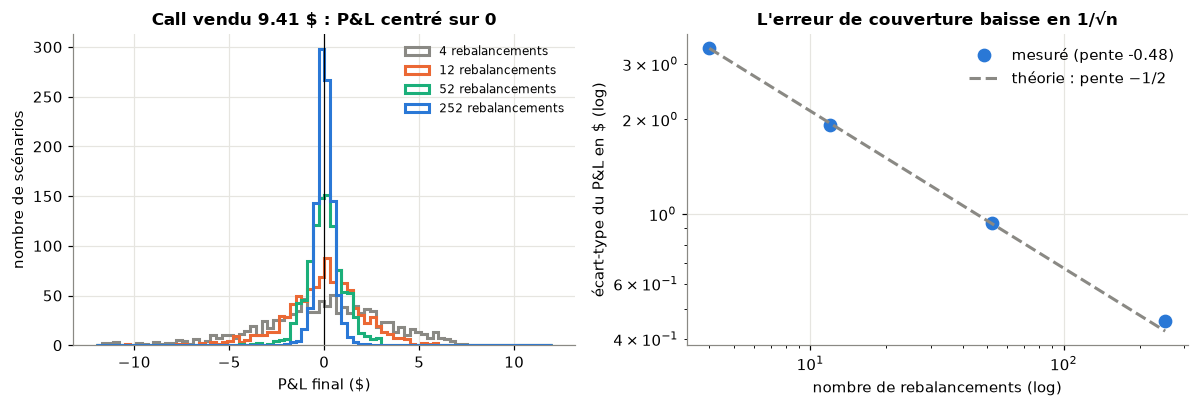

In [2]:
S0, K = 100.0, 100.0
sigma = 0.20
price0 = bs_call(S0, K, T, r, sigma)
delta_fn = lambda S, time_left: bs_delta(S, K, time_left, r, sigma)
payoff_fn = lambda ST: call_payoff(ST, K)

results = {}
for n_steps in [4, 12, 52, 252]: # quarterly, monthly, weekly, daily
    paths = simulate_gbm_paths(S0, r, sigma, np.linspace(0, T, n_steps + 1), n_paths=1000)
    results[n_steps] = delta_hedge_pnl(paths, T, r, price0, delta_fn, payoff_fn)
    p = results[n_steps]
    print(f"{n_steps:>3} rebalancements | P&L moyen {p.mean():+.2f} $ | écart-type {p.std():.2f} $ ({p.std() / price0:.1%} de la prime)")

n_list = np.array(list(results))
stds = np.array([results[n].std() for n in n_list])
slope = np.polyfit(np.log(n_list), np.log(stds), 1)[0] # slope of log(std) against log(n)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(-12, 12, 81)
for (n, p), c in zip(results.items(), [GREY, ORANGE, AQUA, BLUE]):
    axes[0].hist(p, bins=bins, histtype="step", linewidth=2, color=c, label=f"{n} rebalancements")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("P&L final ($)")
axes[0].set_ylabel("nombre de scénarios")
axes[0].set_title(f"Call vendu {price0:.2f} $ : P&L centré sur 0")
axes[0].legend(fontsize=8)
axes[1].loglog(n_list, stds, "o", color=BLUE, markersize=8, label=f"mesuré (pente {slope:.2f})")
axes[1].loglog(n_list, stds[0] * (n_list / n_list[0]) ** -0.5, "--", color=GREY, label="théorie : pente −1/2")
axes[1].set_xlabel("nombre de rebalancements (log)")
axes[1].set_ylabel("écart-type du P&L en $ (log)")
axes[1].set_title("L'erreur de couverture baisse en 1/√n")
axes[1].legend()
plt.tight_layout()
plt.show()

## 2. Brent, données réelles : estimer σ avant le trade

Le 1er janvier, la banque ne connaît que le passé. On compare à la vol réalisée de l'année deux estimateurs de σ :
- la vol historique de l'année d'avant, où tous les jours pèsent pareil ;
- l'EWMA (λ = 0,94), où les jours récents pèsent plus.

historique | erreur absolue moyenne 14.7 pts (sans 2020 : 12.4 pts)
EWMA       | erreur absolue moyenne 11.7 pts (sans 2020 : 8.4 pts)


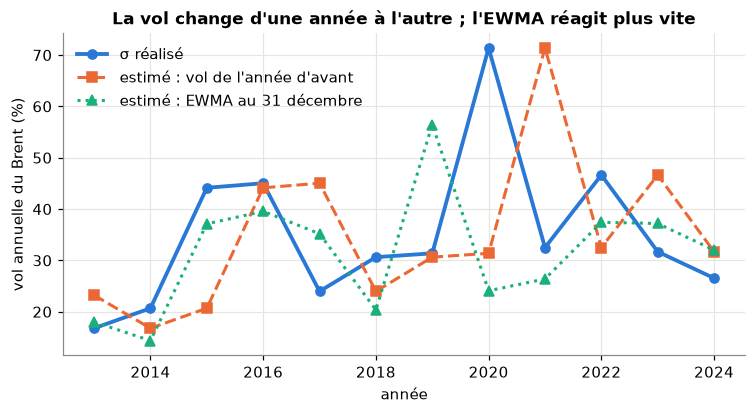

In [3]:
brent = get_prices("BZ=F", "01/01/2012", "31/12/2024")
sigma_real = np.array([historical_vol(brent[str(y)]) for y in years]) # known only at the end of the year
sigma_histo = np.array([historical_vol(brent[str(y - 1)]) for y in years]) # known on January 1st
sigma_ewma = np.array([ewma_vol(brent[str(y - 1)]) for y in years])
not_2020 = np.array(years) != 2020
for name, est in [("historique", sigma_histo), ("EWMA", sigma_ewma)]:
    err = (est - sigma_real) * 100
    print(f"{name:10s} | erreur absolue moyenne {np.abs(err).mean():.1f} pts (sans 2020 : {np.abs(err[not_2020]).mean():.1f} pts)")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(years, sigma_real * 100, "o-", color=BLUE, linewidth=2.5, label="σ réalisé")
ax.plot(years, sigma_histo * 100, "s--", color=ORANGE, label="estimé : vol de l'année d'avant")
ax.plot(years, sigma_ewma * 100, "^:", color=AQUA, label="estimé : EWMA au 31 décembre")
ax.set_xlabel("année")
ax.set_ylabel("vol annuelle du Brent (%)")
ax.set_title("La vol change d'une année à l'autre ; l'EWMA réagit plus vite")
ax.legend()
plt.show()

## 3. Brent, données réelles : 12 calls couverts (2013 à 2024)

Chaque 1er janvier, la banque vend un call d'un an à la monnaie, le price et le couvre chaque jour avec le σ estimé. On refait le même trade en trichant, avec le σ réalisé de l'année : si ce P&L « triche » est proche de 0, la méthode est bonne et l'erreur vient de l'estimation de σ.

historique         | P&L absolu moyen 3.49 $ par baril
EWMA               | P&L absolu moyen 2.15 $ par baril
triche (σ réalisé) | P&L absolu moyen 0.64 $ par baril


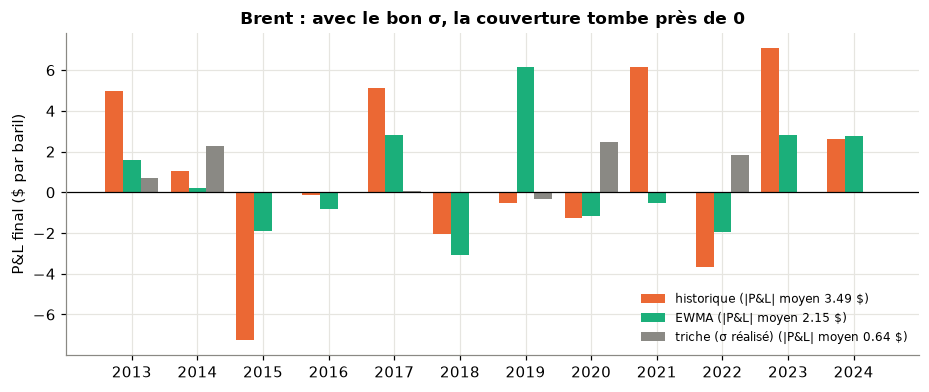

In [4]:
pnl_call = {"historique": [], "EWMA": [], "triche (σ réalisé)": []}
for y, s_h, s_e, s_r in zip(years, sigma_histo, sigma_ewma, sigma_real):
    path = brent[str(y)].to_numpy() # the real year, day by day
    K_y = path[0] # at the money
    for name, s in zip(pnl_call, [s_h, s_e, s_r]):
        price_y = bs_call(path[0], K_y, T, r, s)
        pnl_call[name].append(hedge_one_path(path, T, r, price_y, lambda S, tl: bs_delta(S, K_y, tl, r, s),
                                             lambda ST: call_payoff(ST, K_y)))
pnl_call = {name: np.array(v) for name, v in pnl_call.items()}
for name, v in pnl_call.items():
    print(f"{name:18s} | P&L absolu moyen {np.abs(v).mean():.2f} $ par baril")

x = np.arange(len(years))
fig, ax = plt.subplots(figsize=(10, 3.8))
for shift, (name, v), c in zip([-0.27, 0, 0.27], pnl_call.items(), [ORANGE, AQUA, GREY]):
    ax.bar(x + shift, v, width=0.27, color=c, label=f"{name} (|P&L| moyen {np.abs(v).mean():.2f} $)")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, years)
ax.set_ylabel("P&L final ($ par baril)")
ax.set_title("Brent : avec le bon σ, la couverture tombe près de 0")
ax.legend(fontsize=8)
plt.show()

## 4. Spread, en simulation : quelle méthode de calcul ?

Modèle : deux GBM corrélés (Brent 80 \$, WTI 75 \$, σ 30 % et 35 %, ρ = 0,6). Le Monte Carlo (MC) price n'importe quel spread, mais lentement. On le compare à trois formules :

| Méthode | Domaine | Nature |
|---|---|---|
| Margrabe (1978) | K = 0 seulement | exacte |
| Kirk (1995) | tout K | approximation, standard des desks énergie |
| Bjerksund-Stensland (2014) | tout K | approximation (borne inférieure) |

Monte Carlo 100k      5.371 ms par prix
Margrabe              0.091 ms par prix (59 fois plus rapide que le MC)
Kirk                  0.093 ms par prix (58 fois plus rapide que le MC)
Bjerksund–Stensland   0.142 ms par prix (38 fois plus rapide que le MC)


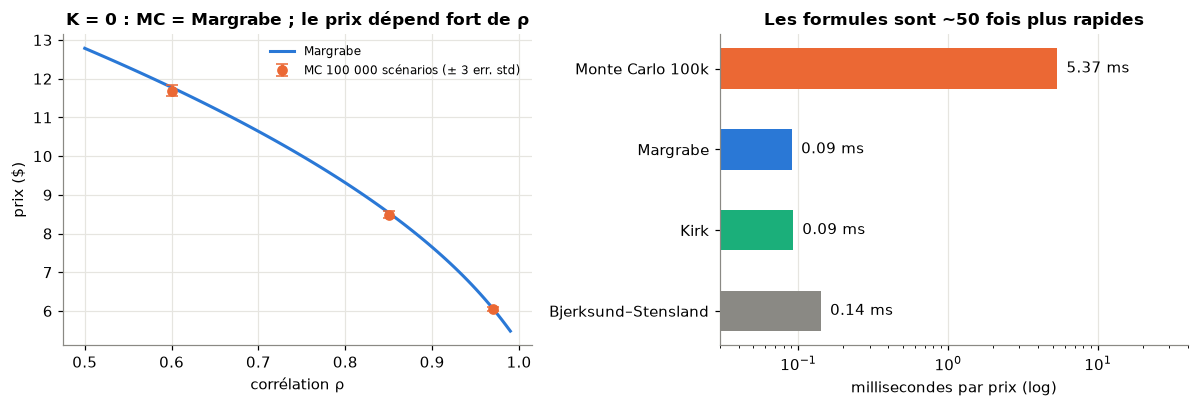

In [5]:
S1_0, S2_0, sigma1, sigma2, rho = 80.0, 75.0, 0.30, 0.35, 0.6

# exactness at K = 0, and speed
rhos_k0 = [0.6, 0.85, 0.97]
mc_k0 = [mc_spread_call(S1_0, S2_0, 0.0, T, r, sigma1, sigma2, x) for x in rhos_k0] # (price, std error)

def time_ms(fn, n_calls):
    start = time.perf_counter()
    for _ in range(n_calls):
        fn()
    return (time.perf_counter() - start) / n_calls * 1000 # milliseconds per call

times = {"Monte Carlo 100k": time_ms(lambda: mc_spread_call(S1_0, S2_0, 5.0, T, r, sigma1, sigma2, rho), 20),
         "Margrabe": time_ms(lambda: margrabe_call(S1_0, S2_0, T, sigma1, sigma2, rho), 2000),
         "Kirk": time_ms(lambda: kirk_call(S1_0, S2_0, 5.0, T, r, sigma1, sigma2, rho), 2000),
         "Bjerksund–Stensland": time_ms(lambda: bjerksund_stensland_call(S1_0, S2_0, 5.0, T, r, sigma1, sigma2, rho), 2000)}
for name, t in times.items():
    ratio = "" if name.startswith("Monte") else f" ({times['Monte Carlo 100k'] / t:.0f} fois plus rapide que le MC)"
    print(f"{name:20s} {t:6.3f} ms par prix{ratio}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
rho_grid = np.linspace(0.5, 0.99, 100)
axes[0].plot(rho_grid, [margrabe_call(S1_0, S2_0, T, sigma1, sigma2, x) for x in rho_grid], color=BLUE, label="Margrabe")
axes[0].errorbar(rhos_k0, [m[0] for m in mc_k0], yerr=[3 * m[1] for m in mc_k0], fmt="o", color=ORANGE,
                 capsize=4, label="MC 100 000 scénarios (± 3 err. std)")
axes[0].set_xlabel("corrélation ρ")
axes[0].set_ylabel("prix ($)")
axes[0].set_title("K = 0 : MC = Margrabe ; le prix dépend fort de ρ")
axes[0].legend(fontsize=8)
axes[1].barh(list(times), list(times.values()), color=[ORANGE, BLUE, AQUA, GREY], height=0.5)
for i, t in enumerate(times.values()):
    axes[1].text(t * 1.15, i, f"{t:.2f} ms", va="center")
axes[1].set_xscale("log")
axes[1].set_xlim(0.03, 40)
axes[1].invert_yaxis()
axes[1].grid(axis="y", visible=False)
axes[1].set_xlabel("millisecondes par prix (log)")
axes[1].set_title("Les formules sont ~50 fois plus rapides")
plt.tight_layout()
plt.show()

Pour K ≠ 0 il n'y a pas de formule exacte : la référence est un MC de 10 millions de scénarios (5 × 2M).

Kirk                 | erreur absolue moyenne 0.84 ct | max 3.96 ct
Bjerksund–Stensland  | erreur absolue moyenne 0.40 ct | max 1.25 ct


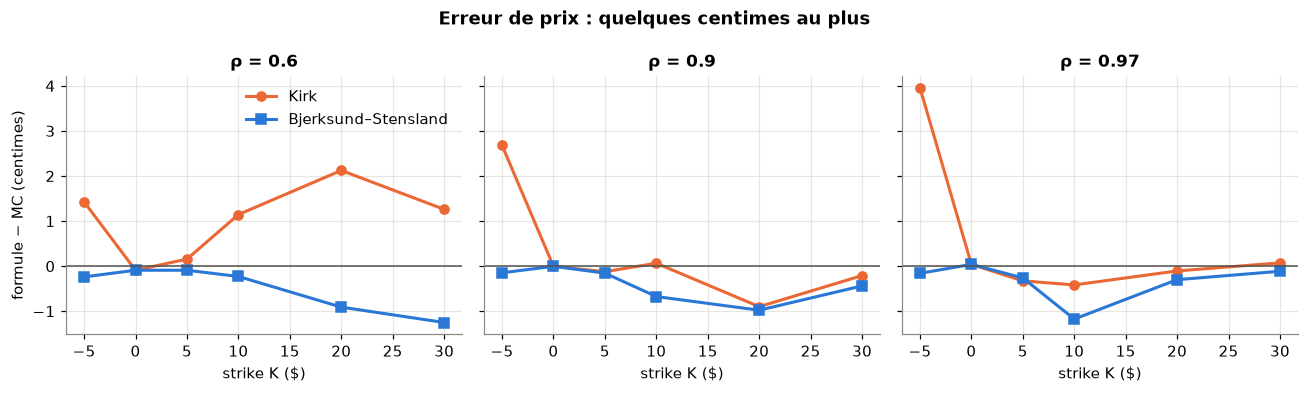

In [6]:
strikes = [-5.0, 0.0, 5.0, 10.0, 20.0, 30.0]
err_kirk, err_bs = {}, {} # formula - MC reference, in cents
for rho_test in [0.6, 0.9, 0.97]:
    err_kirk[rho_test], err_bs[rho_test] = [], []
    for K_test in strikes:
        ref = np.mean([mc_spread_call(S1_0, S2_0, K_test, T, r, sigma1, sigma2, rho_test, n_paths=2_000_000, seed=s)[0]
                       for s in range(101, 106)])
        err_kirk[rho_test].append(100 * (kirk_call(S1_0, S2_0, K_test, T, r, sigma1, sigma2, rho_test) - ref))
        err_bs[rho_test].append(100 * (bjerksund_stensland_call(S1_0, S2_0, K_test, T, r, sigma1, sigma2, rho_test) - ref))
for name, errs in [("Kirk", err_kirk), ("Bjerksund–Stensland", err_bs)]:
    all_errs = np.abs(np.concatenate(list(errs.values())))
    print(f"{name:20s} | erreur absolue moyenne {all_errs.mean():.2f} ct | max {all_errs.max():.2f} ct")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, rho_test in zip(axes, [0.6, 0.9, 0.97]):
    ax.plot(strikes, err_kirk[rho_test], "o-", color=ORANGE, label="Kirk")
    ax.plot(strikes, err_bs[rho_test], "s-", color=BLUE, label="Bjerksund–Stensland")
    ax.axhline(0, color="#52514e", linewidth=1)
    ax.set_xlabel("strike K ($)")
    ax.set_title(f"ρ = {rho_test}")
axes[0].set_ylabel("formule − MC (centimes)")
axes[0].legend()
fig.suptitle("Erreur de prix : quelques centimes au plus", fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Spread, en simulation : la couverture avec les deltas de Kirk

Call sur spread K = 5, vendu au prix de Kirk et couvert chaque jour sur les deux jambes (achat de Brent, vente de WTI), 1 000 scénarios.

prime 9.05 $ | P&L moyen +0.025 $ | écart-type 0.565 $ (6.2% de la prime) | pire 5 % -0.84 $


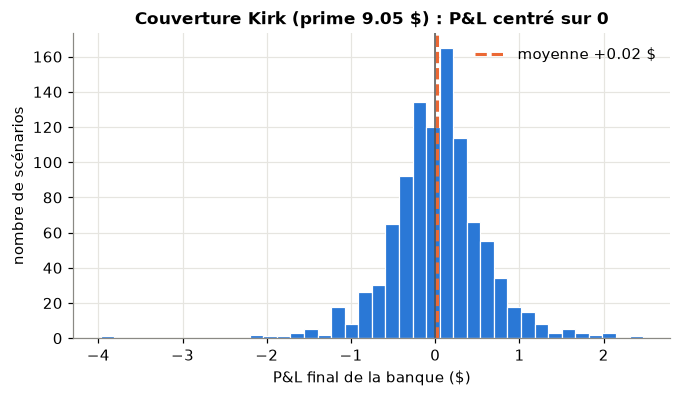

In [7]:
K = 5.0
obs_times = np.linspace(0, T, 253) # daily
paths1, paths2 = simulate_bivariate_gbm_paths(S1_0, S2_0, r, sigma1, sigma2, rho, obs_times, n_paths=1000)
price_kirk = kirk_call(S1_0, S2_0, K, T, r, sigma1, sigma2, rho)
pnl_kirk = delta_hedge_spread_pnl(paths1, paths2, T, r, price_kirk,
                                  lambda S1, S2, tl: kirk_deltas(S1, S2, K, tl, r, sigma1, sigma2, rho),
                                  lambda S1T, S2T: spread_call_payoff(S1T, S2T, K))
print(f"prime {price_kirk:.2f} $ | P&L moyen {pnl_kirk.mean():+.3f} $ | écart-type {pnl_kirk.std():.3f} $ "
      f"({pnl_kirk.std() / price_kirk:.1%} de la prime) | pire 5 % {np.quantile(pnl_kirk, 0.05):+.2f} $")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(pnl_kirk, bins=40, color=BLUE, edgecolor="white", linewidth=0.8)
ax.axvline(0, color="#52514e", linewidth=1)
ax.axvline(pnl_kirk.mean(), color=ORANGE, linestyle="--", label=f"moyenne {pnl_kirk.mean():+.2f} $")
ax.set_xlabel("P&L final de la banque ($)")
ax.set_ylabel("nombre de scénarios")
ax.set_title(f"Couverture Kirk (prime {price_kirk:.2f} $) : P&L centré sur 0")
ax.legend()
plt.show()

## 6. Crack spread, données réelles : 12 calls couverts avec Kirk

Spread retenu : le crack US, 42 × fioul (HO=F, cotée en \$/gallon, 42 gallons par baril) moins WTI (CL=F). On retire le 20/04/2020, jour où le WTI a clôturé à −37,63 \$.

Chaque 1er janvier, la banque vend un call d'un an à la monnaie, pricé et couvert avec Kirk. σ1, σ2 et ρ sont estimés sur l'année d'avant (historique ou EWMA). Pour savoir quel paramètre coûte le plus, on remplace les estimations par les valeurs réalisées, d'abord ρ seul, puis les vols seules, puis tout.

erreur absolue moyenne sur ρ (historique) : 0.115
erreur absolue moyenne sur ρ (EWMA) : 0.100
historique             | P&L absolu moyen 4.36 $ par baril
EWMA                   | P&L absolu moyen 2.37 $ par baril
EWMA + ρ réalisé       | P&L absolu moyen 2.05 $ par baril
EWMA + σ réalisés      | P&L absolu moyen 1.36 $ par baril
triche (tout réalisé)  | P&L absolu moyen 0.55 $ par baril


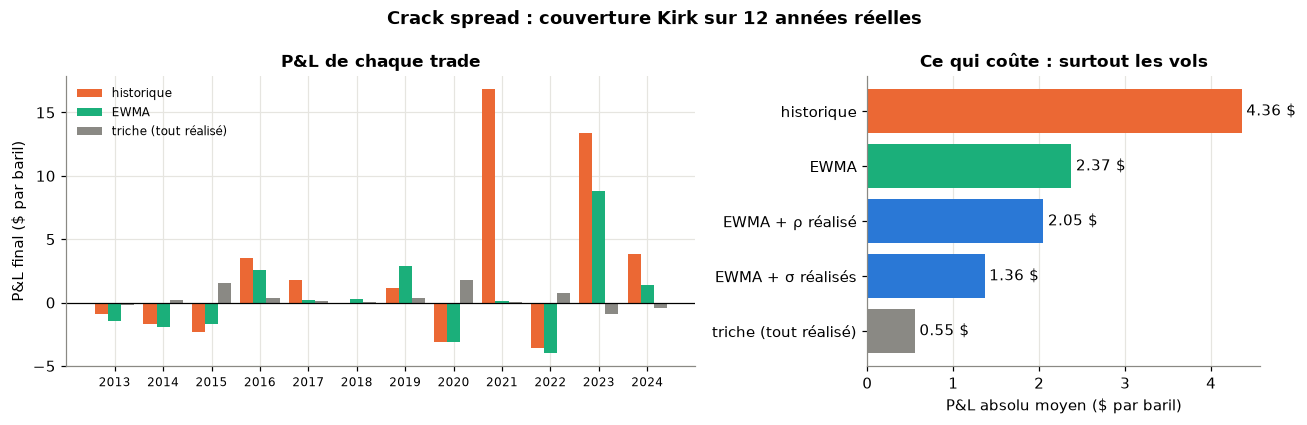

In [8]:
both = get_prices(["HO=F", "CL=F"], "01/01/2012", "31/12/2024")
both = both[(both > 0).all(axis=1)] # drop 20/04/2020, the negative WTI day
heating, wti = 42 * both["HO=F"], both["CL=F"]

names = ["historique", "EWMA", "EWMA + ρ réalisé", "EWMA + σ réalisés", "triche (tout réalisé)"]
pnl_crack = {name: [] for name in names}
rho_err = {"historique": [], "EWMA": []}
for y in years:
    before, now = str(y - 1), str(y)
    p1, p2 = heating[now].to_numpy(), wti[now].to_numpy()
    K_y = p1[0] - p2[0] # at the money
    histo = (historical_vol(heating[before]), historical_vol(wti[before]), historical_corr(heating[before], wti[before]))
    ewma = (ewma_vol(heating[before]), ewma_vol(wti[before]), ewma_corr(heating[before], wti[before]))
    real = (historical_vol(heating[now]), historical_vol(wti[now]), historical_corr(heating[now], wti[now]))
    rho_err["historique"].append(abs(histo[2] - real[2]))
    rho_err["EWMA"].append(abs(ewma[2] - real[2]))
    params = [histo, ewma, (ewma[0], ewma[1], real[2]), (real[0], real[1], ewma[2]), real]
    for name, (s1, s2, rh) in zip(names, params):
        price_y = kirk_call(p1[0], p2[0], K_y, T, r, s1, s2, rh)
        deltas_fn = lambda a, b, tl: kirk_deltas(a, b, K_y, tl, r, s1, s2, rh)
        pnl_crack[name].append(hedge_spread_one_path(p1, p2, T, r, price_y, deltas_fn,
                                                     lambda S1T, S2T: spread_call_payoff(S1T, S2T, K_y)))
pnl_crack = {name: np.array(v) for name, v in pnl_crack.items()}
for name, v in rho_err.items():
    print(f"erreur absolue moyenne sur ρ ({name}) : {np.mean(v):.3f}")
for name, v in pnl_crack.items():
    print(f"{name:22s} | P&L absolu moyen {np.abs(v).mean():.2f} $ par baril")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={"width_ratios": [1.6, 1]})
for shift, name, c in zip([-0.27, 0, 0.27], ["historique", "EWMA", "triche (tout réalisé)"], [ORANGE, AQUA, GREY]):
    axes[0].bar(x + shift, pnl_crack[name], width=0.27, color=c, label=name)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_xticks(x, years, fontsize=8)
axes[0].set_ylabel("P&L final ($ par baril)")
axes[0].set_title("P&L de chaque trade")
axes[0].legend(fontsize=8)
values = [np.abs(pnl_crack[name]).mean() for name in names]
bars = axes[1].barh(names, values, color=[ORANGE, AQUA, BLUE, BLUE, GREY])
axes[1].bar_label(bars, fmt="%.2f $", padding=3)
axes[1].invert_yaxis()
axes[1].grid(axis="y", visible=False)
axes[1].set_xlabel("P&L absolu moyen ($ par baril)")
axes[1].set_title("Ce qui coûte : surtout les vols")
fig.suptitle("Crack spread : couverture Kirk sur 12 années réelles", fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Bilan

| Étape | Résultat |
|---|---|
| Call, couverture simulée | P&L moyen ≈ 0 ; écart-type 4,8 % de la prime en quotidien, en baisse comme 1/√n |
| Brent, estimation de σ | erreur absolue moyenne 14,7 pts (historique), 11,7 pts (EWMA) |
| Brent, couverture réelle | \|P&L\| moyen 3,49 \$ (historique), 2,15 \$ (EWMA), 0,64 \$ avec le σ réalisé |
| Spread, méthodes | Kirk et Bjerksund-Stensland à moins de 4 centimes du MC, 40 à 60 fois plus rapides |
| Spread, couverture simulée | Kirk : P&L moyen +0,03 \$, écart-type 6,2 % de la prime |
| Crack, couverture réelle | \|P&L\| moyen 4,36 \$ (historique), 2,37 \$ (EWMA), 0,55 \$ avec tout réalisé |

Ce qu'on en retient :
- Quand le modèle est vrai, la couverture marche, pour le call (Black-Scholes) comme pour le spread (Kirk).
- Sur données réelles, la perte vient surtout des paramètres, et d'abord des volatilités : connaître les vols réalisées ramène le crack de 2,37 \$ à 1,36 \$, connaître ρ seulement à 2,05 \$.
- L'EWMA fait mieux que la vol historique sur ces 12 années, mais 12 trades ne suffisent pas pour conclure fermement.